# Ola Ride Insights - Exploratory Data Analysis

Covers the *Data Understanding & Exploration* and *Cleaning & Preprocessing* steps of the brief. Run `python -m src.etl` first (already done in the zip) so `data/processed/` exists.

**Contents:** 1 Load · 2 Structure · 3 Missing values · 4 Univariate · 5 Bivariate · 6 Time patterns · 7 Anomalies · 8 Takeaways

In [1]:
import sys, warnings; sys.path.insert(0, '..'); warnings.filterwarnings('ignore')
import pandas as pd, numpy as np, matplotlib.pyplot as plt, seaborn as sns
from src import config as C
sns.set_theme(style='whitegrid', context='notebook', palette='viridis')
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
df = pd.read_csv(C.CLEAN_CSV, parse_dates=['Booking_Timestamp', 'Booking_Date'])
ok = df[df.Is_Success == 1]
print(df.shape)

(103024, 34)


## 1 · Structure

In [2]:
df.dtypes.to_frame('dtype').T

,Booking_ID,Booking_Timestamp,Booking_Date,Booking_Time,Booking_Hour,Day_Name,Day_Of_Week,Week_Of_Month,Is_Weekend,Time_Band,...,Customer_Rating,Canceled_Rides_by_Customer,Canceled_Rides_by_Driver,Cancel_Party,Cancel_Reason,Incomplete_Rides,Incomplete_Rides_Reason,Is_Incomplete,Flag_Same_Pickup_Drop,Flag_Fare_Outlier
dtype,str,datetime64[us],datetime64[us],str,int64,str,int64,int64,int64,str,...,float64,str,str,str,str,str,str,float64,int64,int64


In [3]:
df.head(3).T

,0,1,2
Booking_ID,CNR4197668379,CNR4091573505,CNR7037451850
Booking_Timestamp,2024-07-01 00:00:00,2024-07-01 00:00:00,2024-07-01 00:02:00
Booking_Date,2024-07-01 00:00:00,2024-07-01 00:00:00,2024-07-01 00:00:00
Booking_Time,00:00:00,00:00:00,00:02:00
Booking_Hour,0,0,0
Day_Name,Monday,Monday,Monday
Day_Of_Week,1,1,1
Week_Of_Month,1,1,1
Is_Weekend,0,0,0
Time_Band,Night,Night,Night


## 2 · Missing values - are they *random* or *structural*?

Every NULL below is explained by business logic (e.g. no rating if the ride never happened). They are deliberately **not imputed**.

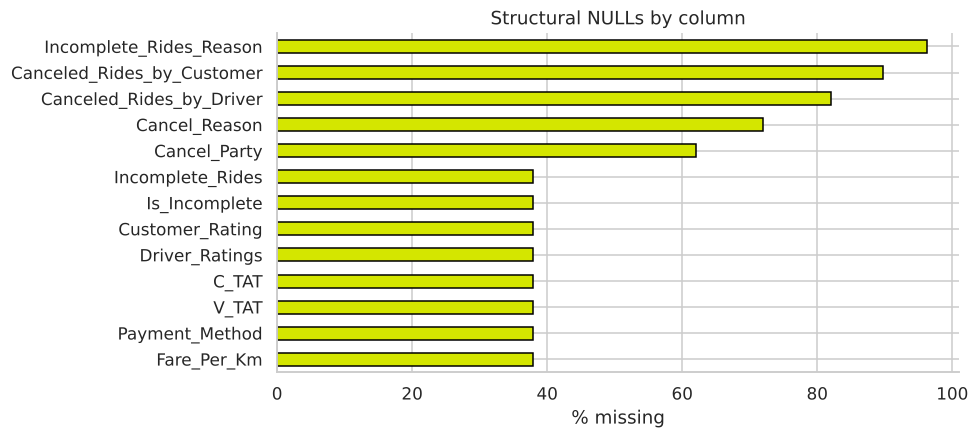

True


In [4]:
na = df.isna().mean().mul(100).round(1).loc[lambda s: s > 0].sort_values()
ax = na.plot.barh(figsize=(8, 4), color='#D4E600', edgecolor='k'); ax.set_xlabel('% missing'); ax.set_title('Structural NULLs by column')
plt.show()
# proof: all payment/rating/TAT fields are populated exactly for successful rides
print((df[['Payment_Method','Driver_Ratings','Customer_Rating','V_TAT','C_TAT']].notna().all(axis=1) == (df.Booking_Status=='Success')).all())

## 3 · Univariate

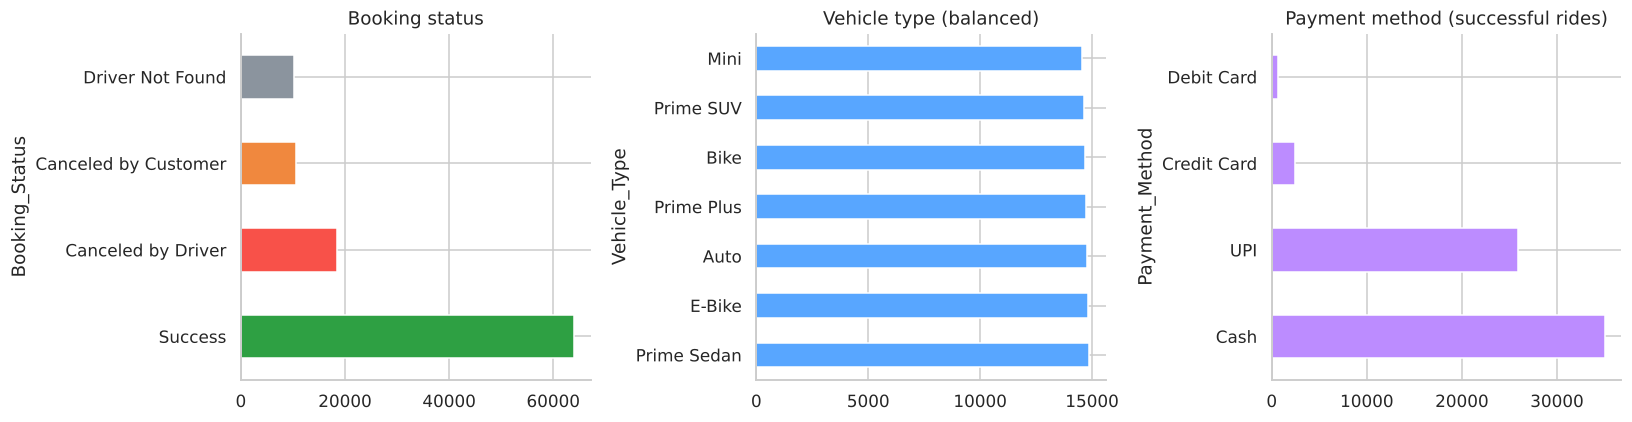

In [5]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
df.Booking_Status.value_counts().plot.barh(ax=ax[0], color=['#2EA043','#F85149','#F0883E','#8B949E']); ax[0].set_title('Booking status')
df.Vehicle_Type.value_counts().plot.barh(ax=ax[1], color='#58A6FF'); ax[1].set_title('Vehicle type (balanced)')
ok.Payment_Method.value_counts().plot.barh(ax=ax[2], color='#BC8CFF'); ax[2].set_title('Payment method (successful rides)')
plt.tight_layout(); plt.show()

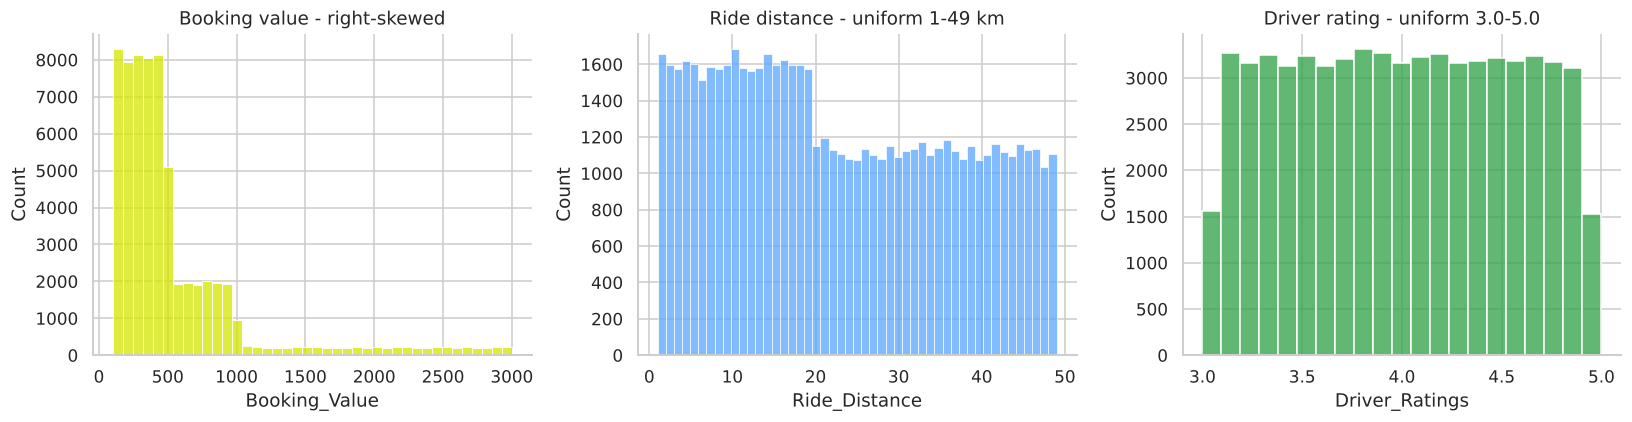

,Booking_Value,Ride_Distance,Driver_Ratings,Customer_Rating,V_TAT,C_TAT
count,63967.00,63967.00,63967.00,63967.00,63967.00,63967.00
mean,548.42,22.85,4.00,4.00,170.88,84.87
std,536.65,14.24,0.58,0.58,80.80,36.01
min,100.00,1.00,3.00,3.00,35.00,25.00
25%,242.00,10.00,3.50,3.50,98.00,55.00
50%,385.00,21.00,4.00,4.00,168.00,85.00
75%,622.00,35.00,4.50,4.50,238.00,115.00
max,2999.00,49.00,5.00,5.00,308.00,145.00


In [6]:
fig, ax = plt.subplots(1, 3, figsize=(15, 4))
sns.histplot(ok.Booking_Value, bins=40, ax=ax[0], color='#D4E600'); ax[0].set_title('Booking value - right-skewed')
sns.histplot(ok.Ride_Distance, bins=49, ax=ax[1], color='#58A6FF'); ax[1].set_title('Ride distance - uniform 1-49 km')
sns.histplot(ok.Driver_Ratings, bins=21, ax=ax[2], color='#2EA043'); ax[2].set_title('Driver rating - uniform 3.0-5.0')
plt.tight_layout(); plt.show()
ok[['Booking_Value','Ride_Distance','Driver_Ratings','Customer_Rating','V_TAT','C_TAT']].describe().round(2)

## 4 · Bivariate - what drives what?

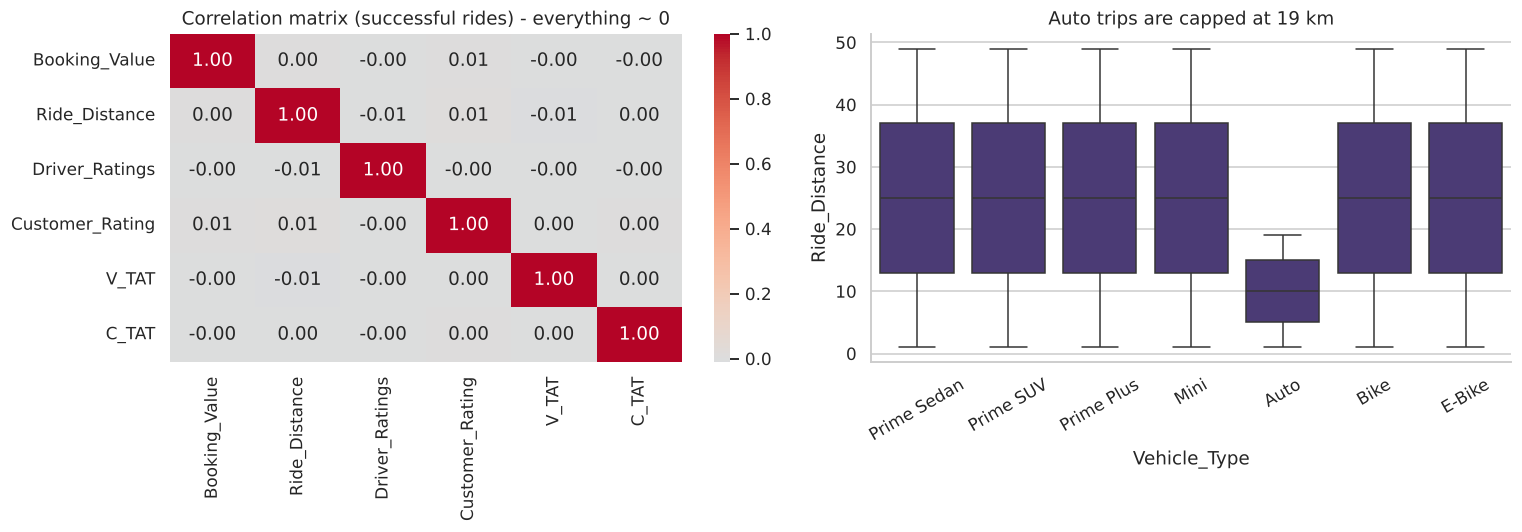

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(ok[['Booking_Value','Ride_Distance','Driver_Ratings','Customer_Rating','V_TAT','C_TAT']].corr(), annot=True, fmt='.2f', cmap='coolwarm', center=0, ax=ax[0])
ax[0].set_title('Correlation matrix (successful rides) - everything ~ 0')
sns.boxplot(data=ok, x='Vehicle_Type', y='Ride_Distance', order=C.VEHICLE_ORDER, ax=ax[1]); ax[1].tick_params(axis='x', rotation=30)
ax[1].set_title('Auto trips are capped at 19 km')
plt.tight_layout(); plt.show()

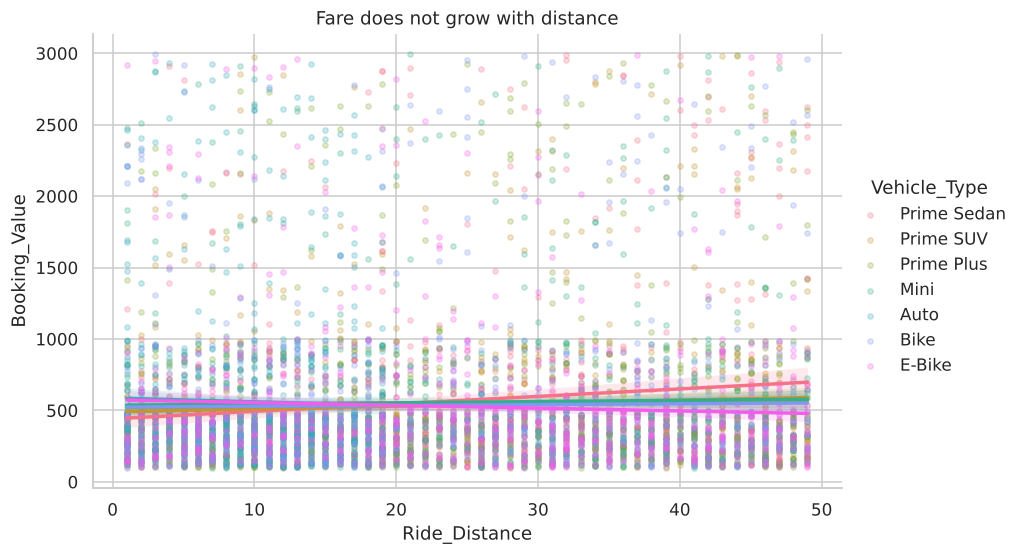

In [8]:
sns.lmplot(data=ok.sample(6000, random_state=1), x='Ride_Distance', y='Booking_Value', hue='Vehicle_Type', hue_order=C.VEHICLE_ORDER, scatter_kws={'alpha':.25,'s':12}, height=5, aspect=1.6)
plt.title('Fare does not grow with distance'); plt.show()

## 5 · Cancellations

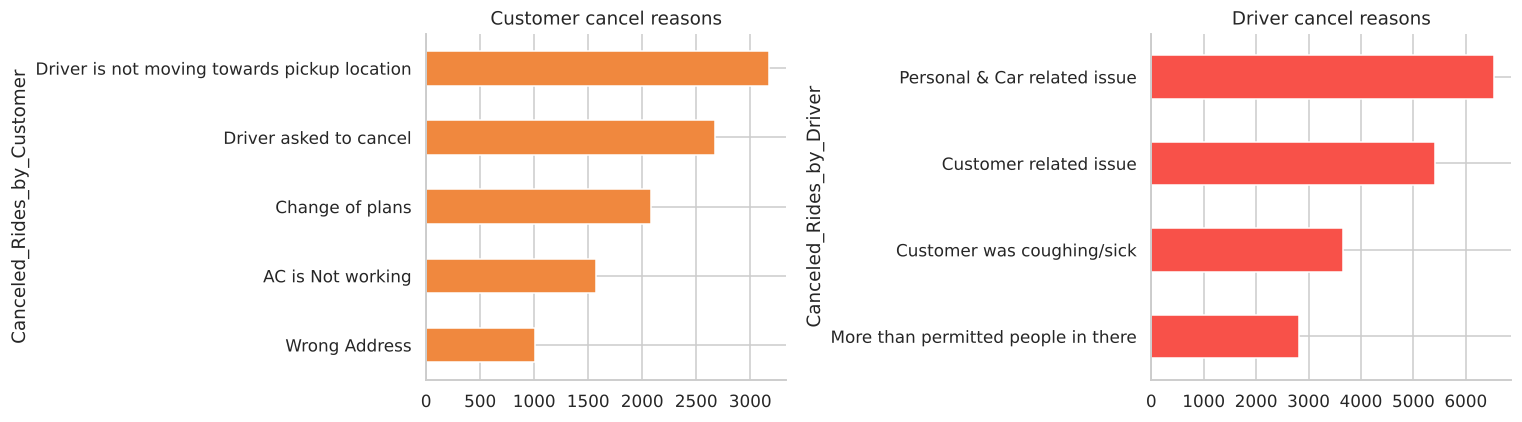

Booking_Status,Canceled by Customer,Canceled by Driver,Driver Not Found,Success
Vehicle_Type,,,,
Prime Sedan,9.9,17.4,9.7,63.0
Prime SUV,10.2,18.1,10.3,61.4
Prime Plus,10.0,18.2,10.0,61.7
Mini,10.3,17.8,9.8,62.1
Auto,10.2,18.1,9.6,62.1
Bike,10.5,17.5,9.8,62.3
E-Bike,10.2,18.2,9.7,62.0


In [9]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
df.Canceled_Rides_by_Customer.value_counts().sort_values().plot.barh(ax=ax[0], color='#F0883E'); ax[0].set_title('Customer cancel reasons')
df.Canceled_Rides_by_Driver.value_counts().sort_values().plot.barh(ax=ax[1], color='#F85149'); ax[1].set_title('Driver cancel reasons')
plt.tight_layout(); plt.show()
pd.crosstab(df.Vehicle_Type, df.Booking_Status, normalize='index').mul(100).round(1).loc[C.VEHICLE_ORDER]

## 6 · Time patterns

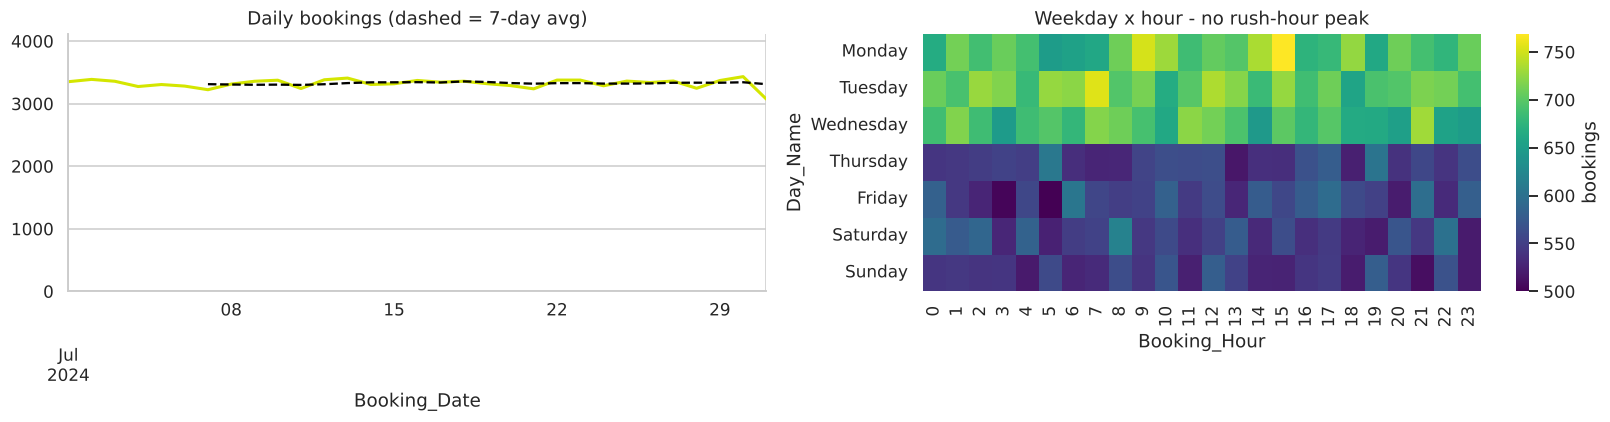

Daily CV = 2.1%  (very stable demand)


In [10]:
daily = df.groupby('Booking_Date').size()
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
daily.plot(ax=ax[0], color='#D4E600', lw=2); daily.rolling(7).mean().plot(ax=ax[0], color='k', ls='--'); ax[0].set_title('Daily bookings (dashed = 7-day avg)'); ax[0].set_ylim(0, daily.max()*1.2)
hm = df.pivot_table(index='Day_Name', columns='Booking_Hour', values='Booking_ID', aggfunc='count').reindex(C.DAY_ORDER)
sns.heatmap(hm, cmap='viridis', ax=ax[1], cbar_kws={'label': 'bookings'}); ax[1].set_title('Weekday x hour - no rush-hour peak')
plt.tight_layout(); plt.show()
print(f'Daily CV = {daily.std()/daily.mean():.1%}  (very stable demand)')

## 7 · Anomalies & data-integrity flags

In [11]:
print('Same pickup & drop on a successful ride :', int(df.Flag_Same_Pickup_Drop.sum()))
print('Fare-per-km outliers (Tukey, log scale)  :', int(df.Flag_Fare_Outlier.sum()))
print('Customers with 2+ customer-cancellations :', int((df[df.Booking_Status=='Canceled by Customer'].Customer_ID.value_counts() >= 2).sum()))
print('Fare vs distance correlation              :', round(ok.Booking_Value.corr(ok.Ride_Distance), 4))
ok.loc[ok.Flag_Fare_Outlier == 1, ['Booking_ID','Vehicle_Type','Ride_Distance','Booking_Value','Fare_Per_Km']].sort_values('Fare_Per_Km', ascending=False).head(5)

Same pickup & drop on a successful ride : 1306
Fare-per-km outliers (Tukey, log scale)  : 1151
Customers with 2+ customer-cancellations : 381
Fare vs distance correlation              : 0.0019


,Booking_ID,Vehicle_Type,Ride_Distance,Booking_Value,Fare_Per_Km
92639,CNR9360526727,E-Bike,1,2981,2981.0
74296,CNR7114242598,Auto,1,2940,2940.0
47770,CNR3047071055,Prime Plus,1,2932,2932.0
82666,CNR6466436239,Auto,1,2928,2928.0
99745,CNR9021264849,E-Bike,1,2920,2920.0


## 8 · Takeaways

1. **62.1 %** of bookings succeed; ~38 % of booking value never converts - conversion, not demand, is the problem.
2. Demand is flat across hours/days; **no rush-hour pattern** - allocation should follow failure hot-spots.
3. **91.6 %** of customers booked exactly once - retention opportunity.
4. Fare is statistically independent of distance (r ≈ 0) - audit the pricing field before using it for pricing decisions.
5. Auto is capped at 19 km yet earns the same average fare - highest revenue per km.
6. Ratings are uniform 3-5 with no 1-2★ values - likely inflated or floored.

*Next:* `sql/` for the same questions in SQL, `app/` for the interactive dashboard.